# Lab 3 v2 — Exercise 2: Fine-Tuning `DistilBERT` on IMDB Binary Classification

**Vai trò của Notebook:** Đây là **Executable Report** trình bày trực quan toàn bộ quy trình **Data Audit/EDA (Layer 6) → Baseline trước fine-tune vs Sau fine-tune trên Validation (Layer 7–8.1) → Held-Out Test 1 lần (Layer 8.2) → Error Analysis (Layer 9) → Live Inference (Layer 10)** từ các artifacts tại `experiments/lab3_v2/`.

> **Lưu ý vận hành:** Quá trình fine-tune thật chạy qua CLI (`python labs/lab3_v2/train_ex2.py` và `python labs/lab3_v2/eval_ex2.py`) để có progress bar log, TensorBoard và chống Test leakage; notebook này **không tự train lại**.
>
> **Tài liệu liên quan:** [`REPORT.md`](REPORT.md) · [`docs/eda_report.md`](docs/eda_report.md) · [`docs/experiment_report.md`](docs/experiment_report.md) · [`docs/evaluation_report.md`](docs/evaluation_report.md)

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import display, Image as IPyImage

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / 'labs' / 'lab3_v2').exists():
    REPO_ROOT = REPO_ROOT.parents[1]
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import labs.lab3_v2.config as cfg

print(f'Repo Root  : {REPO_ROOT}')
print(f'Model      : {cfg.EX2_MODEL_NAME} | num_labels={cfg.NUM_LABELS} | max_length={cfg.MAX_LENGTH}')
print(f'IMDB Split : Train={cfg.TRAIN_SUBSET_SIZE:,} / Val={cfg.VAL_SUBSET_SIZE:,} / Test={cfg.TEST_SUBSET_SIZE:,} (seed={cfg.SEED})')
print(f'Train HPs  : epochs={cfg.EPOCH} | lr={cfg.LR} | train_bs={cfg.BATCH_SIZE} | eval_bs={cfg.EVAL_BATCH_SIZE} | wd={cfg.WEIGHT_DECAY}')

Repo Root  : D:\notworLe\Desktop\gitvanhub\Deeplearning-UTH
Model      : distilbert-base-uncased | num_labels=2 | max_length=256
IMDB Split : Train=4,000 / Val=1,000 / Test=1,000 (seed=248)
Train HPs  : epochs=3 | lr=2e-05 | train_bs=16 | eval_bs=32 | wd=0.01


## Layer 6 — Kiểm Toán Dữ Liệu & EDA Trên Tập Con IMDB (`4,000 / 1,000 / 1,000`)

=== collection_report.json ===
{
  "dataset": "imdb",
  "label_names": [
    "Negative",
    "Positive"
  ],
  "raw_train_total": 25000,
  "raw_test_total": 25000,
  "seed": 248,
  "split_sizes": {
    "train": 4000,
    "validation": 1000,
    "test": 1000
  }
}
=== cleaning_report.json ===
{
  "empty_or_whitespace_texts": {
    "train": 0,
    "validation": 0,
    "test": 0
  },
  "reviews_with_html_br_tag": {
    "train": 2341,
    "validation": 586,
    "test": 553
  },
  "internal_exact_duplicates": {
    "train": 3,
    "validation": 0,
    "test": 0
  },
  "cross_split_exact_duplicates": {
    "train_val": 2,
    "train_test": 0,
    "val_test": 1
  },
  "note": "Giữ nguyên văn bản gốc IMDB (không xóa thủ công `<br />`) để bảo toàn tính tái lập của benchmark chuẩn và kiểm chứng khả năng xử lý nhiễu nhẹ của DistilBERT."
}
=== eda_summary.json ===
{
  "max_length": 256,
  "class_counts": {
    "train": {
      "Negative": 2000,
      "Positive": 2000
    },
    "validation": {
   

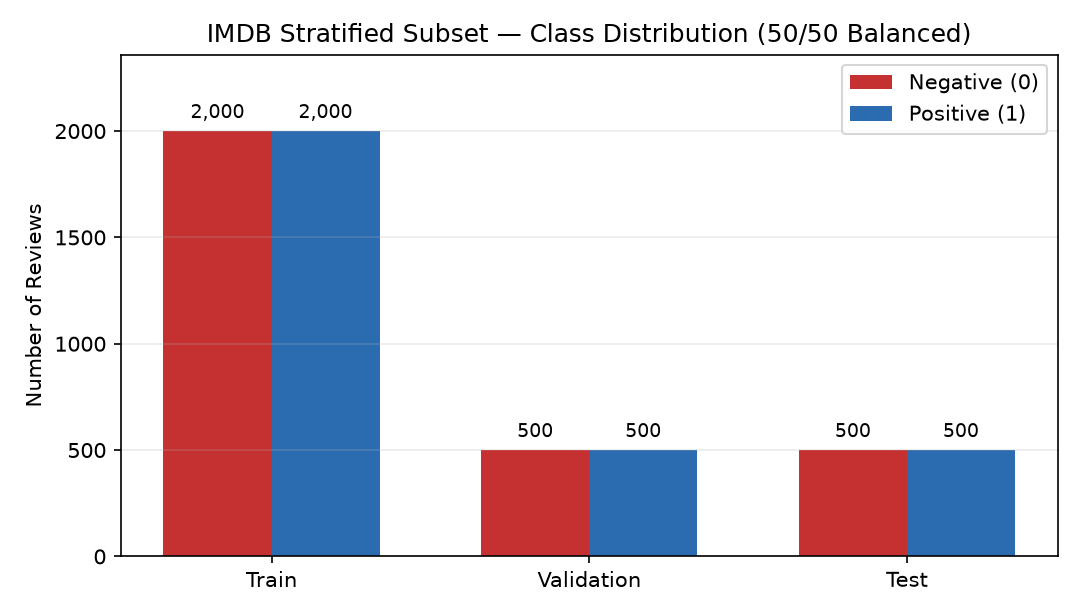

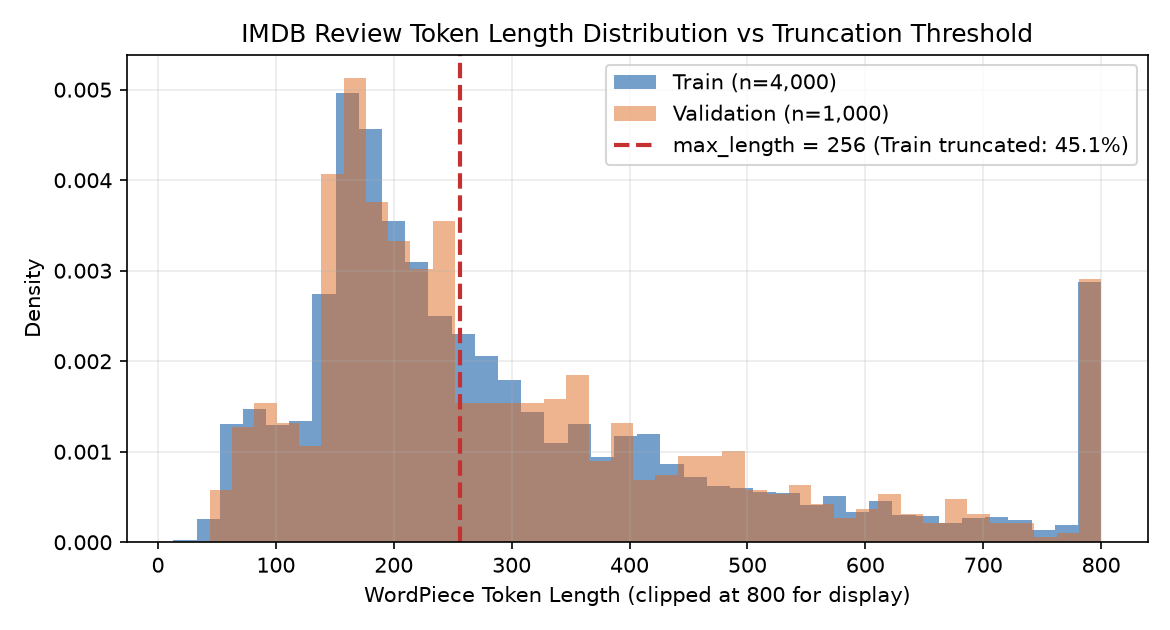

In [2]:
eda_files = ['collection_report.json', 'cleaning_report.json', 'eda_summary.json']
if (cfg.EDA_DIR / 'eda_summary.json').exists():
    for fn in eda_files:
        data = json.loads((cfg.EDA_DIR / fn).read_text(encoding='utf-8'))
        print(f'=== {fn} ===')
        print(json.dumps({k: v for k, v in data.items() if k != 'sample_previews'}, indent=2, ensure_ascii=False))
    for fig in ['eda_class_distribution.png', 'eda_token_length.png']:
        fp = cfg.EDA_DIR / fig
        if fp.exists():
            display(IPyImage(filename=str(fp)))
else:
    print('Chưa có artifacts EDA — Kỹ sư cần chạy Step 4: python labs/lab3_v2/train_ex2.py')

## Layer 7 & 8.1 — Quá Trình Huấn Luyện & So Sánh Trước vs Sau Fine-Tune Trên Validation (`1,000` mẫu)

Gain: Val Acc +38.10 pp | Val F1 +88.11 pp | Train Time: 91.41s | Params: 66,955,010


,"Stage (Val 1,000)",Val Loss,Val Accuracy (%),Val F1 (%)
0,Before Fine-Tune (Baseline),0.6957,49.7,0.00
1,After Fine-Tune (DistilBERT),0.2764,87.8,88.11


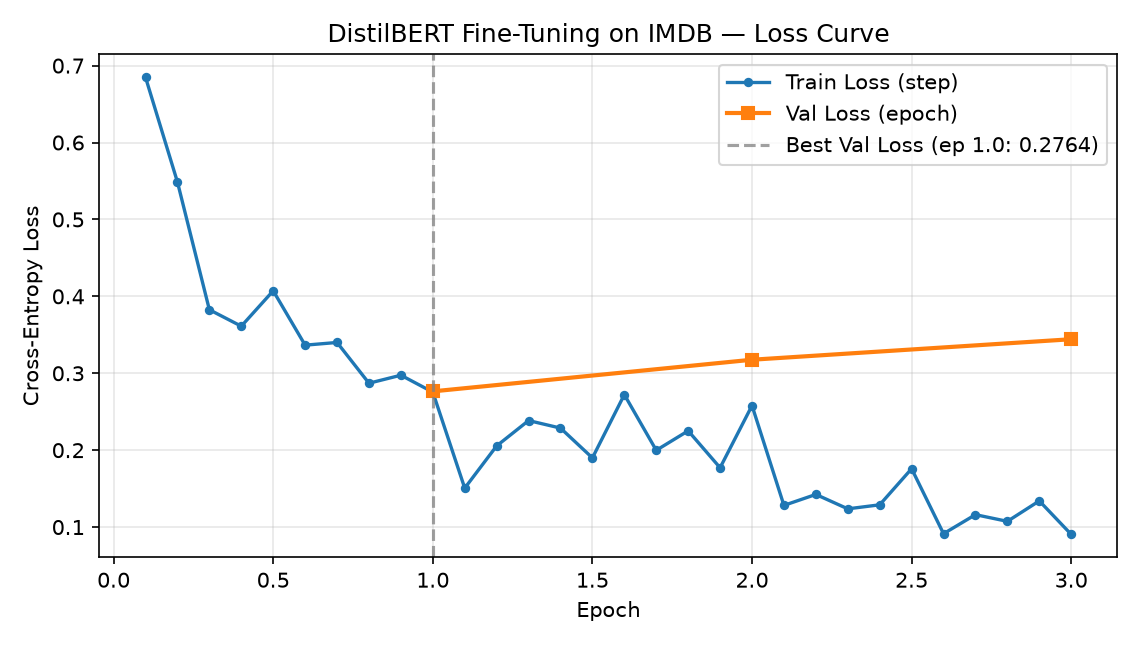

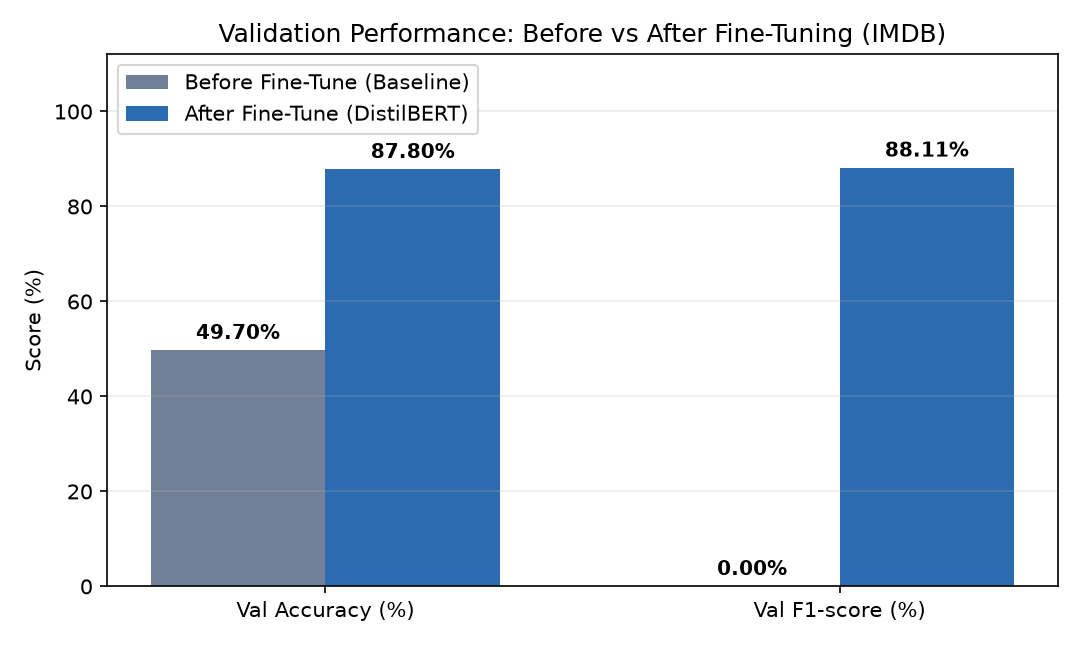

In [3]:
summary_path = cfg.MONITOR_DIR / 'train_summary.json'
if summary_path.exists():
    summary = json.loads(summary_path.read_text(encoding='utf-8'))
    b = summary['baseline_before_finetune']
    a = summary['after_finetune_val']
    cmp_df = pd.DataFrame([
        {
            'Stage (Val 1,000)': 'Before Fine-Tune (Baseline)',
            'Val Loss': round(b['eval_loss'], 4),
            'Val Accuracy (%)': round(b['eval_accuracy'] * 100, 2),
            'Val F1 (%)': round(b['eval_f1'] * 100, 2),
        },
        {
            'Stage (Val 1,000)': 'After Fine-Tune (DistilBERT)',
            'Val Loss': round(a['eval_loss'], 4),
            'Val Accuracy (%)': round(a['eval_accuracy'] * 100, 2),
            'Val F1 (%)': round(a['eval_f1'] * 100, 2),
        },
    ])
    display(cmp_df)
    print(f"Gain: Val Acc {summary['val_accuracy_gain_pp']:+.2f} pp | Val F1 {summary['val_f1_gain_pp']:+.2f} pp | Train Time: {summary['train_time_sec']}s | Params: {summary['param_counts']['total']:,}")
    for fp in [cfg.MONITOR_DIR / 'loss_curve.png', cfg.VAL_EVAL_DIR / 'val_comparison.png']:
        if fp.exists():
            display(IPyImage(filename=str(fp)))
else:
    print('Chưa có train_summary.json — Kỹ sư cần chạy Step 4: python labs/lab3_v2/train_ex2.py')

## Layer 8.2 & 9 — Đánh Giá Cuối Trên Held-Out Test (`1,000` mẫu, 1 Lần) & Phân Tích Lỗi

{
  "split": "test",
  "num_samples": 1000,
  "test_loss": 0.2518,
  "test_accuracy": 0.891,
  "test_f1": 0.8926,
  "test_macro_f1": 0.891,
  "per_class": {
    "Negative": {
      "precision": 0.9031,
      "recall": 0.876,
      "f1": 0.8893,
      "support": 500
    },
    "Positive": {
      "precision": 0.8796,
      "recall": 0.906,
      "f1": 0.8926,
      "support": 500
    }
  },
  "confusion_matrix": [
    [
      438,
      62
    ],
    [
      47,
      453
    ]
  ],
  "truncation_slice": {
    "max_length": 256,
    "truncated_samples": 408,
    "truncated_errors": 59,
    "truncated_error_rate_pct": 14.46,
    "non_truncated_samples": 592,
    "non_truncated_errors": 50,
    "non_truncated_error_rate_pct": 8.45
  }
}
Total Test Errors: 109/1000 (10.9%)
Truncation Slice: {"max_length": 256, "truncated_samples": 408, "truncated_errors": 59, "truncated_error_rate_pct": 14.46, "non_truncated_samples": 592, "non_truncated_errors": 50, "non_truncated_error_rate_pct": 8.45}


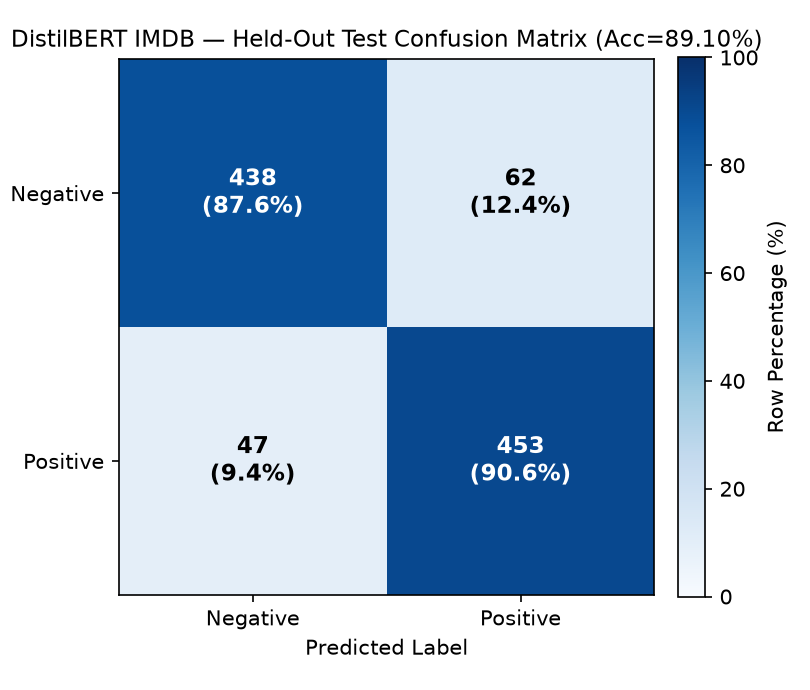

,test_idx,true_label,pred_label,pred_confidence,orig_token_len,was_truncated,text_snippet
0,745,Positive,Negative,0.9654,987,True,1969 was the year. New York City was the place. Putney Swoope was the second Robert Downey film to achieve some recognition. The first was Chaffed Elbows (1966). Putney Swoope achieved a much wider release. Pound (1970) and Greasers Palace (1972) were even more profane and obnoxious. Those 2 films were mean spirited to the point that they actually stalled the Prince's feature film career for several years.<br /><br /
1,231,Positive,Negative,0.9646,455,True,"Tipping the Velvet has just three weeks ago been released in the UK and already I watch as countless letters flood to the national papers and TV guides, claiming that it possesses a thin plot, weak performances and an even weaker script.<br /><br />You find me incensed. This is heresy.<br /><br />I would really like to dispel all doubt by first congratulating Andrew Davies on enabling Geoffrey Sax to create this wond"
2,0,Positive,Negative,0.9584,218,False,"Okay, this may not be the most sophisticated movie you'll ever see. Actually, there isn't a bit of ""sophisticatedlyness""* in it. It's puerile, adolescent, inoffensive, idiotic..And utterly hilarious. Basically, Richie and Eddie run the worst hotel in Britain. Cue some ridiculous antics with the guests while they beat each other up, try to get the rent money out of the only resident who is daft enough to stay, have an"
3,551,Negative,Positive,0.9572,66,False,"This film features two of my favorite guilty pleasures. Sure, the effects are laughable, the story confused, but just watching Hasselhoff in his Knight Rider days is always fun. I especially like the old hotel they used to shoot this in, it added to what little suspense was mustered. Give it a 3."
4,233,Negative,Positive,0.9559,252,False,"Not as bad as some people say...This is a unofficial Bond movie and a remake of ""Thunderball"", written by Kevin McClory (co- producer in ""Thunderball""). Well, the cast is very very interesting, Maria Brandauer is a great Bond- villain, Kim Basinger and Barbara Carrera are just like the ""original"" Bond- girls, plus Rowan Atkinson and a truly great Edward Fox, who looks really refreshing in the ""M"" role. In fact, the w"
5,269,Positive,Negative,0.9555,614,True,"First of all , you should watch this only if you don't mind the lack of subtitles , pornography , kinky sex and utter , horrifying and truly shocking depravity . I mentioned kinky sex , but to call sex in the second half of the movie "" kinky "" would be a great understatement . It's more like a punch in the face if you aren't prepared for this sort of sickness . That being said , I can go back to reviewing this morbid"


In [4]:
test_metrics_path = cfg.TEST_EVAL_DIR / 'final_test_metrics.json'
err_path = cfg.TEST_EVAL_DIR / 'error_examples.json'
if test_metrics_path.exists():
    tm = json.loads(test_metrics_path.read_text(encoding='utf-8'))
    print(json.dumps({k: v for k, v in tm.items() if k != 'artifacts'}, indent=2, ensure_ascii=False))
    cm_fp = cfg.TEST_EVAL_DIR / 'confusion_matrix.png'
    if cm_fp.exists():
        display(IPyImage(filename=str(cm_fp)))
    if err_path.exists():
        err = json.loads(err_path.read_text(encoding='utf-8'))
        print(f"Total Test Errors: {err['total_errors']}/{err['total_test_samples']} ({err['error_rate_pct']}%)")
        print('Truncation Slice:', json.dumps(err['truncation_slice'], ensure_ascii=False))
        err_df = pd.DataFrame(err['high_confidence_errors'][:6])[
            ['test_idx', 'true_label', 'pred_label', 'pred_confidence', 'orig_token_len', 'was_truncated', 'text_snippet']
        ]
        display(err_df)
else:
    print('Chưa có final_test_metrics.json — Kỹ sư cần chạy: python labs/lab3_v2/eval_ex2.py')

## Layer 10 — Kiểm Chứng Suy Luận Trực Tiếp Trên Câu Review Mới (`@torch.inference_mode()`)

In [5]:
if cfg.BEST_MODEL_DIR.exists():
    from src.vibe_scripts.lab3_v2.ex2_finetune import predict_texts
    demo_reviews = [
        'An unforgettable masterpiece with sharp writing and extraordinary performances.',
        'A tedious, poorly acted mess that felt twice as long as its runtime.',
        'The visuals were stunning, though the incoherent story ultimately left me disappointed.',
    ]
    preds = predict_texts(demo_reviews, model_dir=cfg.BEST_MODEL_DIR, max_length=cfg.MAX_LENGTH)
    display(pd.DataFrame(preds))
else:
    print('Chưa có checkpoint best_model/ — bỏ qua live inference cho tới sau Step 4.')

,text,predicted_id,predicted_label,confidence,probabilities,token_count,requires_grad
0,An unforgettable masterpiece with sharp writing and extraordinary performances.,1,Positive,0.9619,"{'Negative': 0.0381, 'Positive': 0.9619}",15,False
1,"A tedious, poorly acted mess that felt twice as long as its runtime.",0,Negative,0.9673,"{'Negative': 0.9673, 'Positive': 0.0327}",19,False
2,"The visuals were stunning, though the incoherent story ultimately left me disappointed.",0,Negative,0.8751,"{'Negative': 0.8751, 'Positive': 0.1249}",19,False
